# Unsupervised Clustering of US City Level-Set Persistence with Wasserstein Diagram Distance

This notebook replicates `cluster_us_city_persistence_landscapes.ipynb`, but clusters samples from pairwise Wasserstein distances between the H1 persistence diagrams in `h1_pairs.csv` instead of from persistence-landscape vectors.

Workflow:

1. Load H1 diagrams from `figs/test_us_cities/manually_filtered_01`.
2. Parse city and morphology labels from folder names for validation only.
3. Optionally normalize each diagram to its own filtration span, matching the scale normalization used in the landscape notebook.
4. Compute the pairwise persistence-diagram Wasserstein distance matrix.
5. Cluster directly from that precomputed distance matrix with average-linkage hierarchical clustering.
6. Visualize the distance matrix with a dendrogram, MDS, and t-SNE.
7. Compare unsupervised clusters against folder labels (`gridiron` versus `cul_de_sac`).
8. Save cluster assignments and the distance matrix.

In [12]:
from pathlib import Path
import os
import re
import warnings

# Keep matplotlib/IPython caches inside writable locations when running from a sandboxed environment.
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mplconfig')
os.environ.setdefault('IPYTHONDIR', '/tmp/ipython')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '8')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from scipy.optimize import linear_sum_assignment
from scipy.stats import skew

from sklearn.manifold import MDS, TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

## 1. Load the Dataset

In [13]:
def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "processed_data").exists() and (candidate / "labeled_data").exists():
            return candidate
        nested = candidate / "levelset_urban_ph"
        if (nested / "processed_data").exists() and (nested / "labeled_data").exists():
            return nested
    raise FileNotFoundError(f"Could not find levelset_urban_ph from {start.resolve()}")

LEVELSET_ROOT = find_levelset_root()
NOTEBOOK_DIR = LEVELSET_ROOT / "notebooks_clustering"
DATA_DIR = LEVELSET_ROOT / "processed_data" / "test_us_cities" / "manually_filtered_01"
ASSIGNMENTS_OUT = NOTEBOOK_DIR / 'cluster_us_city_wasserstein_assignments.csv'
DISTANCE_MATRIX_OUT = NOTEBOOK_DIR / 'cluster_us_city_wasserstein_distance_matrix.csv'

LABEL_RE = re.compile(r'(gridiron|cul_de_sac)')
CITY_RE = re.compile(r'^(.+?)_(gridiron|cul_de_sac)_\d+$')

def parse_sample_name(name: str):
    label_match = LABEL_RE.search(name)
    label = label_match.group(1) if label_match else 'unknown'
    city_match = CITY_RE.match(name)
    city = city_match.group(1) if city_match else name
    return city, label

def read_h1_pairs(path: Path) -> np.ndarray:
    # h1_pairs.csv files were written without a header. Coerce in case pandas sees unusual formatting.
    df = pd.read_csv(path, header=None)
    arr = df.iloc[:, :2].apply(pd.to_numeric, errors='coerce').dropna().to_numpy(float)
    arr = arr[np.isfinite(arr).all(axis=1)]
    arr = arr[arr[:, 1] >= arr[:, 0]]
    return arr

def diagram_summary_features(diagram: np.ndarray) -> dict:
    if diagram.size == 0:
        return {
            'pd_count': 0, 'pd_lifetime_mean': 0, 'pd_lifetime_std': 0, 'pd_lifetime_max': 0,
            'pd_lifetime_sum': 0, 'pd_lifetime_q25': 0, 'pd_lifetime_q50': 0, 'pd_lifetime_q75': 0,
            'pd_birth_mean': 0, 'pd_death_mean': 0, 'pd_lifetime_skew': 0,
        }
    birth = diagram[:, 0]
    death = diagram[:, 1]
    lifetime = death - birth
    return {
        'pd_count': len(lifetime),
        'pd_lifetime_mean': float(np.mean(lifetime)),
        'pd_lifetime_std': float(np.std(lifetime)),
        'pd_lifetime_max': float(np.max(lifetime)),
        'pd_lifetime_sum': float(np.sum(lifetime)),
        'pd_lifetime_q25': float(np.quantile(lifetime, 0.25)),
        'pd_lifetime_q50': float(np.quantile(lifetime, 0.50)),
        'pd_lifetime_q75': float(np.quantile(lifetime, 0.75)),
        'pd_birth_mean': float(np.mean(birth)),
        'pd_death_mean': float(np.mean(death)),
        'pd_lifetime_skew': float(skew(lifetime)) if len(lifetime) > 2 else 0.0,
    }

records = []
diagrams_raw = []

for sample_dir in sorted(DATA_DIR.iterdir()):
    if not sample_dir.is_dir():
        continue
    diagram_path = sample_dir / 'h1_pairs.csv'
    if not diagram_path.exists():
        continue

    diagram = read_h1_pairs(diagram_path)
    city, label = parse_sample_name(sample_dir.name)
    birth = diagram[:, 0] if diagram.size else np.array([0.0])
    death = diagram[:, 1] if diagram.size else np.array([0.0])

    records.append({
        'sample': sample_dir.name,
        'city': city,
        'label': label,
        'n_h1_pairs': len(diagram),
        'diagram_min': float(np.min(birth)),
        'diagram_max': float(np.max(death)),
        'diagram_span': float(np.max(death) - np.min(birth)),
    })
    diagrams_raw.append(diagram)

meta = pd.DataFrame(records)


diagram_features = pd.DataFrame([diagram_summary_features(d) for d in diagrams_raw])
meta_features = pd.concat([meta.reset_index(drop=True), diagram_features], axis=1)
print(f'Loaded {len(meta_features)} samples from {DATA_DIR.resolve()}')
display(meta_features.head())
display(meta_features.groupby(['label', 'city']).size().rename('n_samples').reset_index())
display(meta_features[['n_h1_pairs', 'diagram_span', 'pd_lifetime_mean', 'pd_lifetime_sum']].describe())

Loaded 76 samples from /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/processed_data/test_us_cities/manually_filtered_01


,sample,city,label,n_h1_pairs,diagram_min,diagram_max,diagram_span,pd_count,pd_lifetime_mean,pd_lifetime_std,pd_lifetime_max,pd_lifetime_sum,pd_lifetime_q25,pd_lifetime_q50,pd_lifetime_q75,pd_birth_mean,pd_death_mean,pd_lifetime_skew
0,cary_town_cul_de_sac_12,cary_town,cul_de_sac,238,0.0,124.9,124.9,238,4.136134,5.666891,50.5,984.4,1.8,2.70,3.800,4.273529,8.409664,5.242998
1,cary_town_cul_de_sac_13,cary_town,cul_de_sac,181,0.0,109.1,109.1,181,8.625414,10.328912,87.8,1561.2,2.2,4.70,11.300,12.800552,21.425967,3.524273
2,cary_town_cul_de_sac_14,cary_town,cul_de_sac,143,0.0,51.3,51.3,143,9.718182,9.696893,40.9,1389.7,2.2,6.00,12.700,11.452448,21.170629,1.565130
3,cary_town_cul_de_sac_16,cary_town,cul_de_sac,190,0.0,108.5,108.5,190,8.451579,11.409146,108.5,1605.8,2.1,5.05,9.975,11.013158,19.464737,4.560385
4,cary_town_cul_de_sac_18,cary_town,cul_de_sac,97,0.0,95.9,95.9,97,8.249485,10.585928,89.2,800.2,2.1,4.40,11.700,15.077320,23.326804,4.795957


,label,city,n_samples
0,cul_de_sac,cary_town,15
1,cul_de_sac,chandler,3
2,cul_de_sac,charleston,1
3,cul_de_sac,fort_collins,6
4,cul_de_sac,peachtree,5
5,cul_de_sac,philadelphia,4
6,cul_de_sac,santafe,3
7,gridiron,charleston,3
8,gridiron,fort_collins,2
9,gridiron,philadelphia,34


,n_h1_pairs,diagram_span,pd_lifetime_mean,pd_lifetime_sum
count,76.000000,76.000000,76.000000,76.000000
mean,76.894737,95.589474,24.155247,1283.792105
std,51.740784,32.337176,14.695214,383.770545
min,18.000000,41.200000,4.136134,606.100000
25%,36.750000,70.575000,9.701277,1005.175000
50%,64.500000,93.700000,21.189702,1245.100000
75%,108.250000,114.650000,35.632663,1572.350000
max,279.000000,191.400000,66.536364,2101.700000


## 2. Prepare Diagrams for Distance Computation

`NORMALIZE_DIAGRAMS=True` rescales each sample's birth/death coordinates by that sample's filtration span. This mirrors the normalization in the persistence-landscape notebook, where the landscape coordinate and amplitude are made comparable across samples. Set it to `False` if you want absolute-filtration Wasserstein distances.

In [14]:
NORMALIZE_DIAGRAMS = True
WASSERSTEIN_ORDER = 2.0
GROUND_METRIC_ORDER = 2.0

'''
def normalize_diagram(diagram: np.ndarray) -> np.ndarray:
    if diagram.size == 0:
        return diagram.reshape(0, 2)
    lo = float(np.min(diagram[:, 0]))
    hi = float(np.max(diagram[:, 1]))
    span = max(hi - lo, 1e-12)
    return (diagram - lo) / span
'''
def normalize_diagram(diagram: np.ndarray) -> np.ndarray:
    if diagram.size == 0:
        return diagram.reshape(0, 2).astype(float)

    diagram = np.asarray(diagram, dtype=float)

    transformed = np.column_stack([
        diagram[:, 0],                 # birth
        diagram[:, 1] - diagram[:, 0]  # persistence
    ])

    mins = transformed.min(axis=0)
    ranges = transformed.max(axis=0) - mins

    # Constant coordinates are mapped to zero.
    ranges = np.where(ranges > 0, ranges, 1.0)

    return (transformed - mins) / ranges

diagrams = [normalize_diagram(d) if NORMALIZE_DIAGRAMS else d.copy() for d in diagrams_raw]

print('Using normalized diagrams:', NORMALIZE_DIAGRAMS)
print('Wasserstein order:', WASSERSTEIN_ORDER)
print('Ground metric order:', GROUND_METRIC_ORDER)
print(f'Diagram sizes: min={min(len(d) for d in diagrams)}, max={max(len(d) for d in diagrams)}, mean={np.mean([len(d) for d in diagrams]):.1f}')

Using normalized diagrams: True
Wasserstein order: 2.0
Ground metric order: 2.0
Diagram sizes: min=18, max=279, mean=76.9


## 3. Compute Pairwise Wasserstein Distances

The function below computes persistence-diagram Wasserstein distance by solving one linear assignment problem per diagram pair. Points may either match points in the other diagram or match their own projection to the diagonal. The diagonal-to-diagonal block has zero cost, which permits both diagrams to leave different numbers of points unmatched.

The default is W2 with Euclidean ground distance.

In [15]:
def point_to_diagonal_distance_power(diagram: np.ndarray, p: float) -> np.ndarray:
    if diagram.size == 0:
        return np.empty(0, dtype=float)
    lifetime = np.maximum(diagram[:, 1] - diagram[:, 0], 0.0)
    # Euclidean distance from (birth, death) to the diagonal y=x is lifetime / sqrt(2).
    return (lifetime / np.sqrt(2.0)) ** p

def wasserstein_distance_pd(diagram_a: np.ndarray, diagram_b: np.ndarray, order: float = 2.0, ground_order: float = 2.0) -> float:
    a = np.asarray(diagram_a, dtype=float).reshape(-1, 2)
    b = np.asarray(diagram_b, dtype=float).reshape(-1, 2)
    n = len(a)
    m = len(b)

    if n == 0 and m == 0:
        return 0.0
    if n == 0:
        return float(np.sum(point_to_diagonal_distance_power(b, order)) ** (1.0 / order))
    if m == 0:
        return float(np.sum(point_to_diagonal_distance_power(a, order)) ** (1.0 / order))

    # Pairwise ground distances between off-diagonal points.
    diff = a[:, None, :] - b[None, :, :]
    point_cost = np.sum(np.abs(diff) ** ground_order, axis=2) ** (order / ground_order)

    cost = np.full((n + m, n + m), np.inf, dtype=float)
    cost[:n, :m] = point_cost

    # a-points can match their own diagonal copies.
    a_diag_cost = point_to_diagonal_distance_power(a, order)
    for i, c in enumerate(a_diag_cost):
        cost[i, m + i] = c

    # b-points can match their own diagonal copies.
    b_diag_cost = point_to_diagonal_distance_power(b, order)
    for j, c in enumerate(b_diag_cost):
        cost[n + j, j] = c

    # Diagonal copies can match each other at zero cost.
    cost[n:, m:] = 0.0

    row_ind, col_ind = linear_sum_assignment(cost)
    return float(cost[row_ind, col_ind].sum() ** (1.0 / order))

n = len(diagrams)
D = np.zeros((n, n), dtype=float)
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]

for k, (i, j) in enumerate(pairs, start=1):
    D[i, j] = wasserstein_distance_pd(
        diagrams[i], diagrams[j], order=WASSERSTEIN_ORDER, ground_order=GROUND_METRIC_ORDER
    )
    D[j, i] = D[i, j]
    if k % 500 == 0 or k == len(pairs):
        print(f'Computed {k:,} / {len(pairs):,} distances')

nonzero = D[D > 0]
print('Distance matrix shape:', D.shape)
print(f'Min off-diag: {nonzero.min():.6f}, Max: {D.max():.6f}, Mean: {nonzero.mean():.6f}')

Computed 500 / 2,850 distances
Computed 1,000 / 2,850 distances
Computed 1,500 / 2,850 distances
Computed 2,000 / 2,850 distances
Computed 2,500 / 2,850 distances
Computed 2,850 / 2,850 distances
Distance matrix shape: (76, 76)
Min off-diag: 0.152321, Max: 3.617493, Mean: 1.470616


## 4. Average-Linkage Hierarchical Clustering on Wasserstein Distance

In [17]:
condensed_wasserstein = squareform(D, checks=False)
Z = linkage(condensed_wasserstein, method='average')

cluster_labels = fcluster(Z, t=2, criterion='maxclust')
meta_features['cluster'] = cluster_labels - 1

sil_wasserstein = silhouette_score(D, meta_features['cluster'], metric='precomputed')
print(f'Wasserstein-distance silhouette score: {sil_wasserstein:.3f}')
display(meta_features.groupby(['cluster', 'label']).size().unstack(fill_value=0))
display(meta_features.groupby(['cluster', 'city']).size().unstack(fill_value=0))

Wasserstein-distance silhouette score: 0.412


label,cul_de_sac,gridiron
cluster,,
0,35,16
1,2,23


city,cary_town,chandler,charleston,fort_collins,peachtree,philadelphia,santafe
cluster,,,,,,,
0,13,3,3,6,5,18,3
1,2,0,1,2,0,20,0


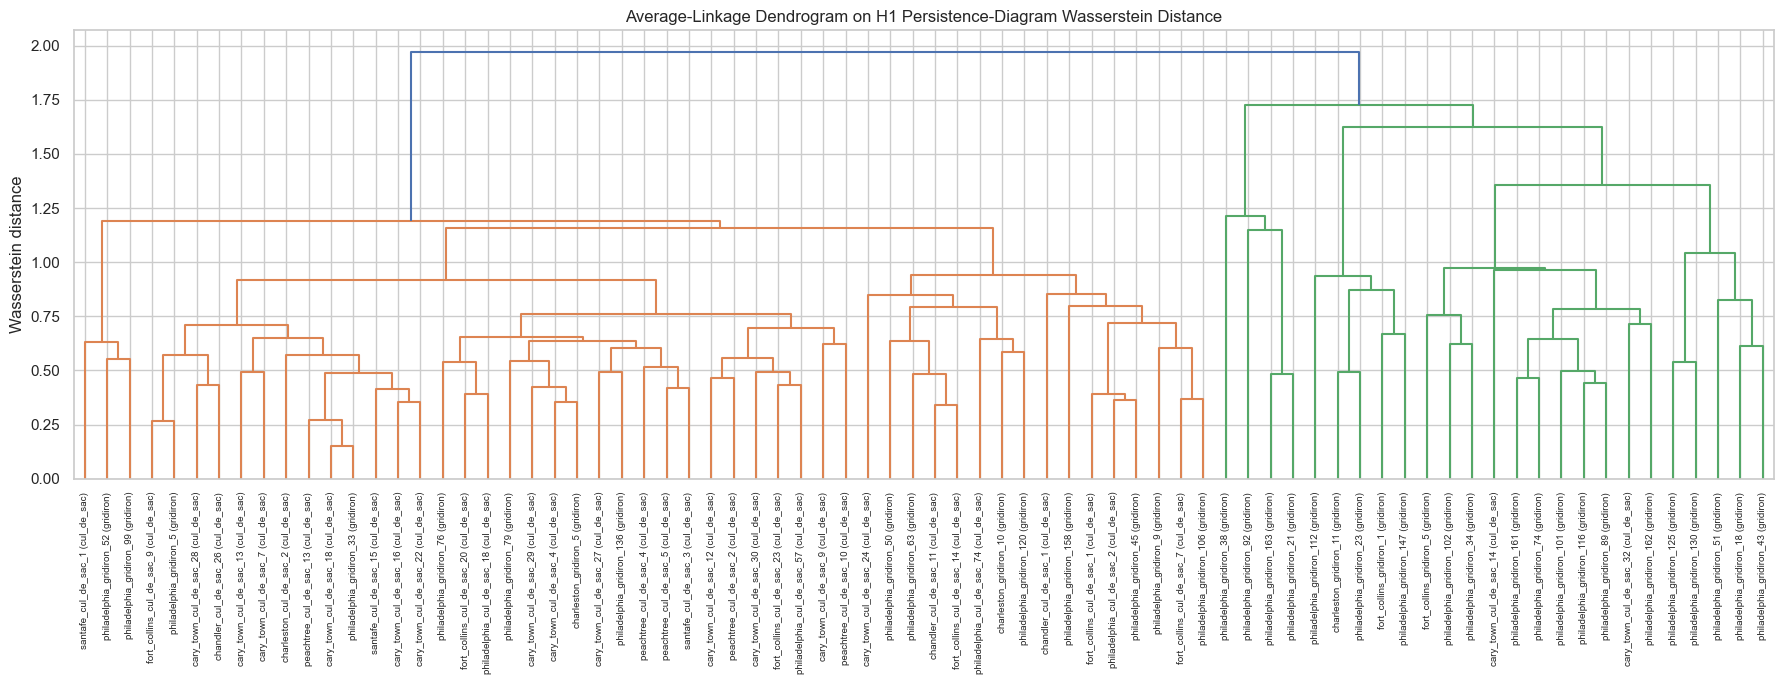

In [18]:
plt.figure(figsize=(18, 7))
leaf_labels = [f"{row.sample} ({row.label})" for row in meta_features.itertuples()]
dendrogram(
    Z,
    labels=leaf_labels,
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=Z[-1, 2],
)
plt.title('Average-Linkage Dendrogram on H1 Persistence-Diagram Wasserstein Distance')
plt.ylabel('Wasserstein distance')
plt.tight_layout()
plt.show()

## 5. MDS and t-SNE Visualizations of the Distance Matrix

In [19]:
mds = MDS(
    n_components=2,
    dissimilarity='precomputed',
    random_state=42,
    normalized_stress='auto',
)
X_mds = mds.fit_transform(D)

tsne = TSNE(
    n_components=2,
    metric='precomputed',
    perplexity=min(30, max(5, (len(meta_features) - 1) // 3)),
    init='random',
    learning_rate='auto',
    random_state=42,
)
X_tsne = tsne.fit_transform(D)

viz = meta_features.copy()
viz['mds1'] = X_mds[:, 0]
viz['mds2'] = X_mds[:, 1]
viz['tsne1'] = X_tsne[:, 0]
viz['tsne2'] = X_tsne[:, 1]

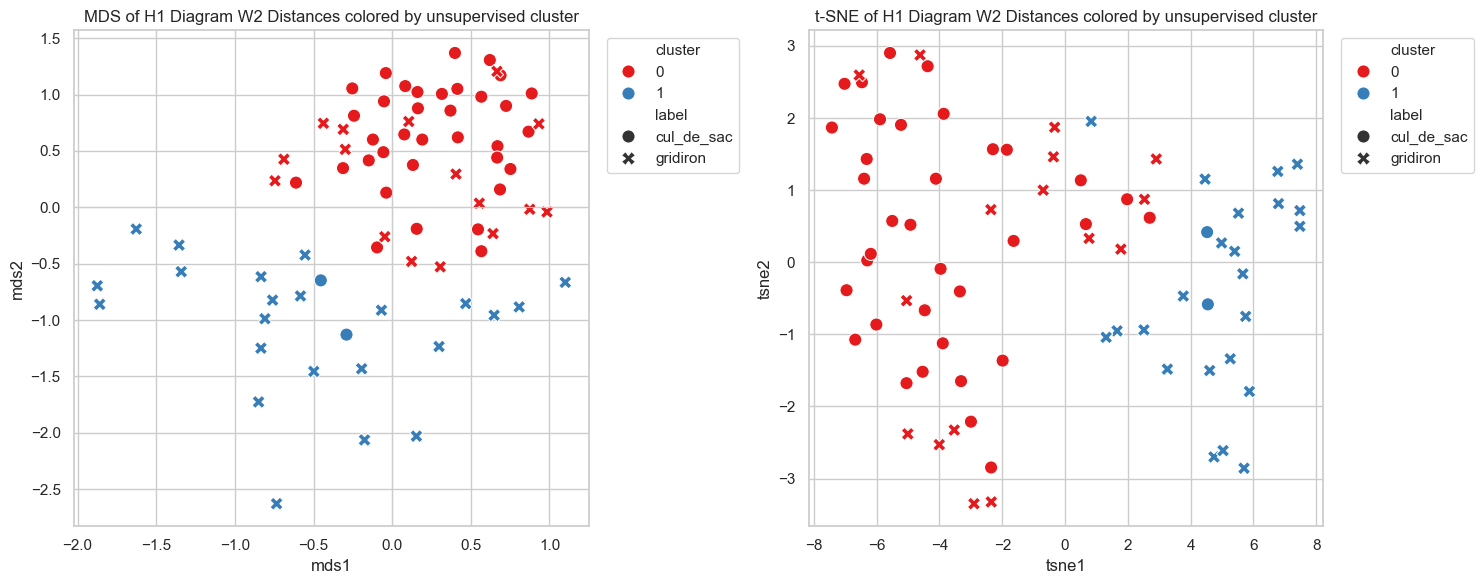

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=viz, x='mds1', y='mds2', hue='cluster', style='label', s=90,
    palette='Set1', ax=axes[0]
)
axes[0].set_title('MDS of H1 Diagram W2 Distances colored by unsupervised cluster')
axes[0].axhline(0, color='0.8', linewidth=0.8)
axes[0].axvline(0, color='0.8', linewidth=0.8)

sns.scatterplot(
    data=viz, x='tsne1', y='tsne2', hue='cluster', style='label', s=90,
    palette='Set1', ax=axes[1]
)
axes[1].set_title('t-SNE of H1 Diagram W2 Distances colored by unsupervised cluster')

for ax in axes:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

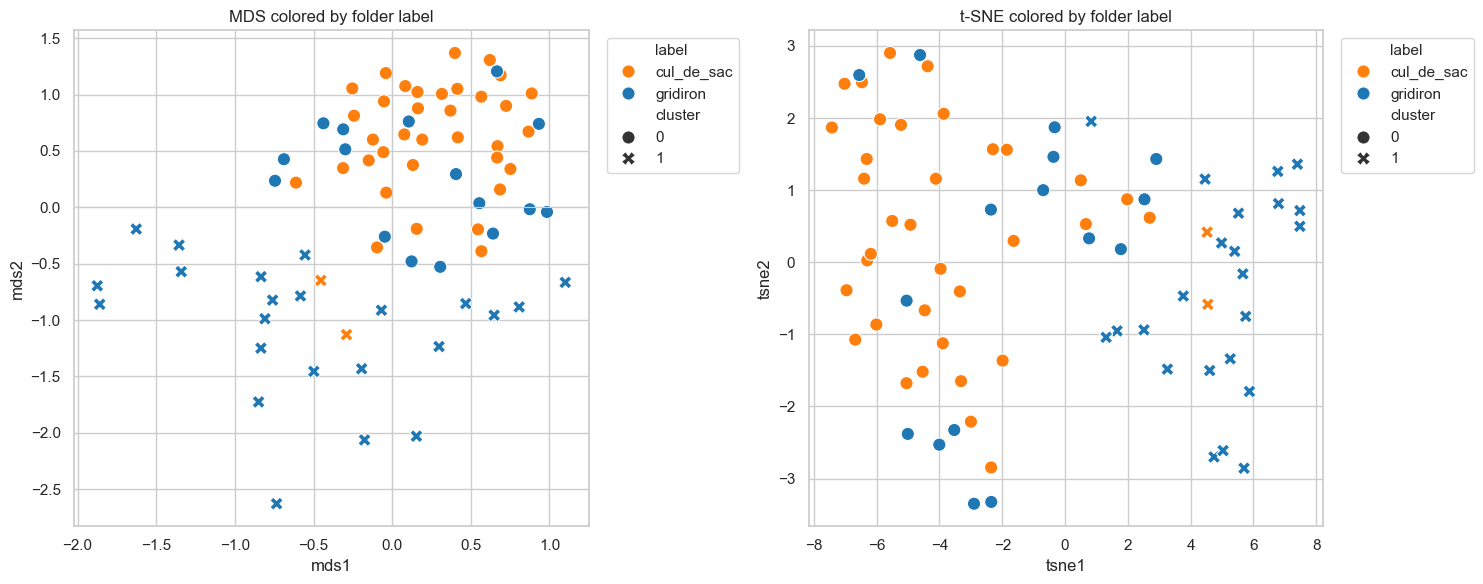

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=viz, x='mds1', y='mds2', hue='label', style='cluster', s=90,
    palette={'gridiron': '#1f77b4', 'cul_de_sac': '#ff7f0e'}, ax=axes[0]
)
axes[0].set_title('MDS colored by folder label')
axes[0].axhline(0, color='0.8', linewidth=0.8)
axes[0].axvline(0, color='0.8', linewidth=0.8)

sns.scatterplot(
    data=viz, x='tsne1', y='tsne2', hue='label', style='cluster', s=90,
    palette={'gridiron': '#1f77b4', 'cul_de_sac': '#ff7f0e'}, ax=axes[1]
)
axes[1].set_title('t-SNE colored by folder label')

for ax in axes:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 6. Compare Clusters Against Known Folder Labels

In [22]:
true_labels = meta_features['label'].map({'gridiron': 0, 'cul_de_sac': 1}).to_numpy()
pred = meta_features['cluster'].to_numpy()

ari = adjusted_rand_score(true_labels, pred)
nmi = normalized_mutual_info_score(true_labels, pred)

# Cluster IDs are arbitrary. Use Hungarian assignment to report best label-matched accuracy.
cm = confusion_matrix(true_labels, pred, labels=[0, 1])
row_ind, col_ind = linear_sum_assignment(-cm)
best_accuracy = cm[row_ind, col_ind].sum() / cm.sum()
cluster_to_label = {int(cluster): ['gridiron', 'cul_de_sac'][int(truth)] for truth, cluster in zip(row_ind, col_ind)}
meta_features['cluster_interpreted_as'] = meta_features['cluster'].map(cluster_to_label)
meta_features['matches_folder_label'] = meta_features['cluster_interpreted_as'] == meta_features['label']
viz['cluster_interpreted_as'] = meta_features['cluster_interpreted_as']
viz['matches_folder_label'] = meta_features['matches_folder_label']

print(f'Adjusted Rand Index: {ari:.3f}')
print(f'Normalized Mutual Information: {nmi:.3f}')
print(f'Best label-matched accuracy: {best_accuracy:.3f}')
print('Cluster interpretation:', cluster_to_label)

display(pd.DataFrame(cm, index=['true_gridiron', 'true_cul_de_sac'], columns=['cluster_0', 'cluster_1']))
display(meta_features.groupby(['cluster', 'cluster_interpreted_as', 'label']).size().rename('n').reset_index())

Adjusted Rand Index: 0.268
Normalized Mutual Information: 0.277
Best label-matched accuracy: 0.763
Cluster interpretation: {1: 'gridiron', 0: 'cul_de_sac'}


,cluster_0,cluster_1
true_gridiron,16,23
true_cul_de_sac,35,2


,cluster,cluster_interpreted_as,label,n
0,0,cul_de_sac,cul_de_sac,35
1,0,cul_de_sac,gridiron,16
2,1,gridiron,cul_de_sac,2
3,1,gridiron,gridiron,23


In [23]:
misclustered = meta_features.loc[~meta_features['matches_folder_label'], [
    'sample', 'city', 'label', 'cluster', 'cluster_interpreted_as', 'n_h1_pairs',
    'pd_lifetime_mean', 'pd_lifetime_max', 'pd_lifetime_sum'
]].sort_values(['label', 'city', 'sample'])

print(f'Misclustered samples under best label mapping: {len(misclustered)} / {len(meta_features)}')
display(misclustered)

Misclustered samples under best label mapping: 18 / 76


,sample,city,label,cluster,cluster_interpreted_as,n_h1_pairs,pd_lifetime_mean,pd_lifetime_max,pd_lifetime_sum
2,cary_town_cul_de_sac_14,cary_town,cul_de_sac,1,gridiron,143,9.718182,40.9,1389.7
11,cary_town_cul_de_sac_32,cary_town,cul_de_sac,1,gridiron,124,9.634677,39.2,1194.7
19,charleston_gridiron_10,charleston,gridiron,0,cul_de_sac,101,18.499010,85.5,1868.4
21,charleston_gridiron_5,charleston,gridiron,0,cul_de_sac,21,52.352381,101.5,1099.4
41,philadelphia_gridiron_106,philadelphia,gridiron,0,cul_de_sac,56,25.698214,84.0,1439.1
44,philadelphia_gridiron_120,philadelphia,gridiron,0,cul_de_sac,64,22.870313,82.3,1463.7
47,philadelphia_gridiron_136,philadelphia,gridiron,0,cul_de_sac,28,47.707143,73.5,1335.8
49,philadelphia_gridiron_158,philadelphia,gridiron,0,cul_de_sac,33,27.439394,58.5,905.5
56,philadelphia_gridiron_33,philadelphia,gridiron,0,cul_de_sac,33,48.966667,112.8,1615.9
60,philadelphia_gridiron_45,philadelphia,gridiron,0,cul_de_sac,40,33.447500,76.2,1337.9


## 7. Interpret the Split With Diagram Summary Statistics

In [ ]:
summary_cols = [
    'n_h1_pairs', 'diagram_span', 'pd_count', 'pd_lifetime_mean', 'pd_lifetime_std',
    'pd_lifetime_max', 'pd_lifetime_sum', 'pd_lifetime_q50', 'pd_lifetime_q75'
]
cluster_summary = meta_features.groupby('cluster')[summary_cols].agg(['mean', 'median', 'std']).round(3)
label_summary = meta_features.groupby('label')[summary_cols].agg(['mean', 'median', 'std']).round(3)

display(cluster_summary)
display(label_summary)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['n_h1_pairs', 'pd_lifetime_mean', 'pd_lifetime_sum']):
    sns.boxplot(data=meta_features, x='cluster', y=col, hue='label', ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 8. Save Cluster Assignments and Distance Matrix

In [ ]:
output_cols = [
    'sample', 'city', 'label', 'cluster', 'cluster_interpreted_as', 'matches_folder_label',
    'n_h1_pairs', 'diagram_span', 'pd_lifetime_mean', 'pd_lifetime_max', 'pd_lifetime_sum',
    'mds1', 'mds2', 'tsne1', 'tsne2'
]

viz[output_cols].to_csv(ASSIGNMENTS_OUT, index=False)
pd.DataFrame(D, index=meta_features['sample'], columns=meta_features['sample']).to_csv(DISTANCE_MATRIX_OUT)

print(f'Wrote {ASSIGNMENTS_OUT.resolve()}')
print(f'Wrote {DISTANCE_MATRIX_OUT.resolve()}')
display(viz[output_cols].head())

## Notes

- The clustering is unsupervised. Folder labels are used only after clustering to interpret and validate the two groups.
- The final cluster labels come from average-linkage hierarchical clustering on the pairwise H1 persistence-diagram Wasserstein distance matrix.
- MDS and t-SNE are visualizations of the same precomputed distance matrix; they are not used to generate the clusters.
- `NORMALIZE_DIAGRAMS=True` makes the diagram comparison closer to the normalized-landscape pipeline. Toggle it to `False` to preserve absolute filtration scale.